# PSD PREDICTION ANALYSIS

In [1]:
import matplotlib.pyplot as plt  # type: ignore
import numpy as np  # type: ignore
import os
import pandas as pd  # type: ignore
from typing import Optional, cast, List, Union

import src.constants as cn
from src.psd_prediction_file_iterator import PSDPredictionFileIterator
from src.psd_prediction_analyzer import PSDPredictionAnalyzer
from src.nl_curve import NLCurve
from src.piecewise_system_discovery import PiecewiseSystemDiscovery
from src.biomodels_iterator import BiomodelsIterator
from src.timecourse_iterator import TimecourseIterator
from src.model import Model
from src.psd_prediction_analyzer import PSDPredictionAnalyzer

# Data analysis

In [2]:
def fileFilter(dct) -> bool:
    if not cn.COL_MAX_FRACTIONAL_REDUCTION in dct:
        return False
    if dct[cn.COL_MAX_FRACTIONAL_REDUCTION] !=  1e-5:
        pass
        #return False
    if dct[cn.COL_REPEAT] > 1:
        pass
        #return False
    return True



In [3]:
def dataframeFilter(df, dct) -> pd.DataFrame:
    new_df = df.copy()
    return new_df[ new_df [cn.COL_AGGREGATION_TYPE] == "model"]

In [4]:
df = PSDPredictionFileIterator.query()
#df = df [ df[cn.COL_SYSTEM_ID] == "BIOMD0000000297"]
df = df.reset_index()
df[[cn.COL_SYSTEM_ID, cn.COL_P50, cn.COL_AUC]]

,system_id,p50,auc
0,BIOMD0000000005,0.000000,0.000000
1,BIOMD0000000005,0.000000,0.500000
2,BIOMD0000000005,0.000000,0.666667
3,BIOMD0000000005,0.000000,0.750000
4,BIOMD0000000005,0.000000,0.800000
...,...,...,...
13516,BIOMD0000001056,0.000000,0.000000
13517,BIOMD0000001057,0.499989,0.578060
13518,BIOMD0000001058,0.999630,0.999734
13519,BIOMD0000001059,0.997745,0.924847


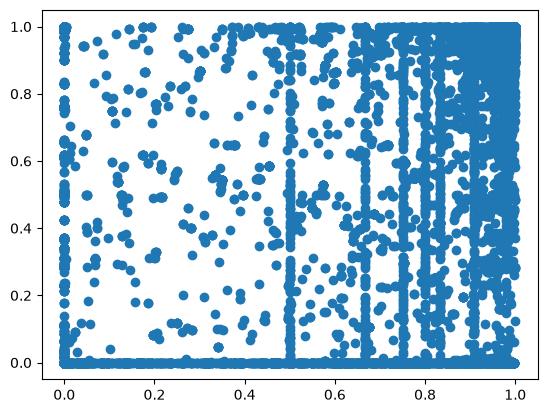

In [5]:
plt.scatter(df[cn.COL_AUC].values, df[cn.COL_P50].values)

In [6]:
#df.loc[df.groupby('A')['B'].idxmin(), ['A', 'B', 'C']]
df1 = df[df[cn.COL_P50] > 0.8]
mask = df1[cn.COL_AUC].isna()
df1 = df1[~mask]
dff = df1.loc[df1.groupby(cn.COL_SYSTEM_ID)[cn.COL_AUC].idxmin(),[cn.COL_SYSTEM_ID,
            cn.COL_NUM_CHANGEPOINT, cn.COL_AUC, cn.COL_P50, cn.COL_FILENAME, cn.COL_CHANGEPOINTS]]
dff

,system_id,num_changepoint,auc,p50,filename,changepoints
7656,BIOMD0000000005,71,0.894968,0.815089,piecewise_predictions__numpoint_100000__thresh...,"[np.int64(20), np.int64(60), np.int64(80), np...."
5979,BIOMD0000000010,1708,0.995878,0.803217,piecewise_predictions__numpoint_100000__thresh...,"[np.int64(20), np.int64(40), np.int64(60), np...."
7658,BIOMD0000000042,529,0.990889,0.903546,piecewise_predictions__numpoint_100000__thresh...,"[np.int64(20), np.int64(160), np.int64(180), n..."
11435,BIOMD0000000234,84,0.960323,0.904478,piecewise_predictions__numpoint_100000__thresh...,"[np.int64(1660), np.int64(1680), np.int64(2400..."
40,BIOMD0000000278,0,0.000000,0.999934,piecewise_predictions__numpoint_100000__thresh...,[]
...,...,...,...,...,...,...
8911,BIOMD0000001056,562,0.671229,0.889174,piecewise_predictions__numpoint_100000__thresh...,"[np.int64(20), np.int64(40), np.int64(60), np...."
4267,BIOMD0000001057,50,0.980392,0.927462,piecewise_predictions__numpoint_100000__thresh...,"[1961, 3922, 5882, 7843, 9804, 11765, 13725, 1..."
8493,BIOMD0000001058,687,0.971053,0.944739,piecewise_predictions__numpoint_100000__thresh...,"[np.int64(20), np.int64(40), np.int64(60), np...."
9336,BIOMD0000001059,1679,0.914472,0.927625,piecewise_predictions__numpoint_100000__thresh...,"[np.int64(20), np.int64(40), np.int64(60), np...."


# AUC and Model Accuracy

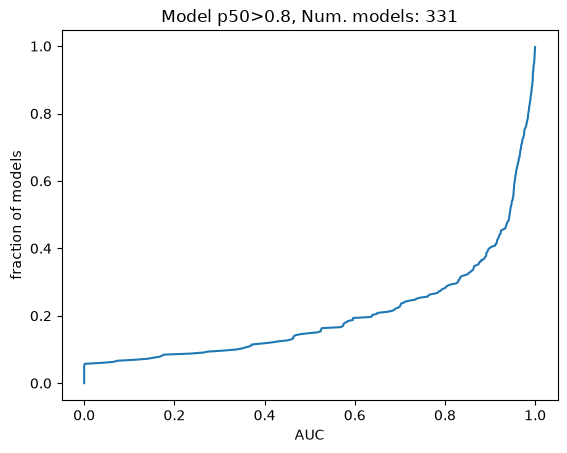

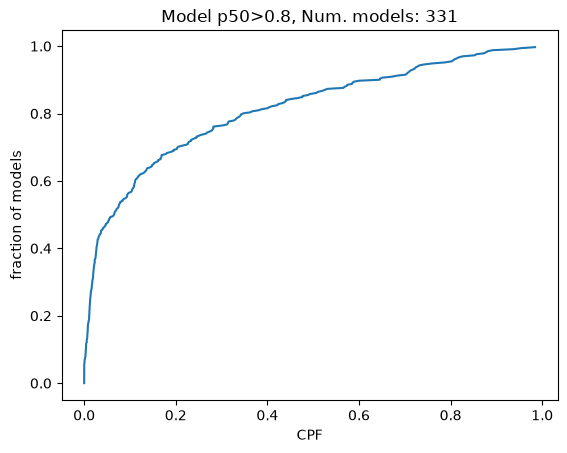

In [7]:
# Parameters
accuracy_threshold = 0.8
statistic = cn.COL_P50
#statistic = cn.COL_MIN

# Data construction
df = PSDPredictionFileIterator.query(file_filter=fileFilter, dataframe_filter=dataframeFilter,
        is_guard_filename=True)
mask = df[cn.COL_AUC].isna()
df = df[~mask]
df = df.reset_index()
df1 = df[df[statistic] > accuracy_threshold]
MODEL_DF = df1.loc[df1.groupby(cn.COL_SYSTEM_ID)[cn.COL_AUC].idxmin(),
    [cn.COL_SYSTEM_ID, cn.COL_NUM_CHANGEPOINT, cn.COL_AUC, cn.COL_P50, cn.COL_MAX, cn.COL_MIN, 
     cn.COL_FILENAME, cn.COL_CHANGEPOINTS]]
MODEL_DF["CPF"] = MODEL_DF[cn.COL_NUM_CHANGEPOINT] / 5000  # Account for lower max values
num_model = len(MODEL_DF[cn.COL_SYSTEM_ID].unique())
fraction_model = np.array(range(num_model))/num_model

sorted_auc = np.sort(MODEL_DF[cn.COL_AUC].values)
plt.plot(sorted_auc, fraction_model)
title = f"Model {statistic}>{accuracy_threshold}, Num. models: {num_model}"
plt.title(title)
plt.xlabel("AUC")
plt.ylabel("fraction of models")
plt.figure()


sorted_auc = np.sort(MODEL_DF["CPF"].values)
plt.plot(sorted_auc, fraction_model)
title = f"Model {statistic}>{accuracy_threshold}, Num. models: {num_model}"
plt.title(title)
plt.xlabel("CPF")
_ = plt.ylabel("fraction of models")

AUC indicates that there are 3 types of models
* Those that are well approximated by a single linear system
* Those that require a modest to significant number of piecewise approximations
* Those that require a very dense series of piecewise approximations

# AUC vs. Changepoints

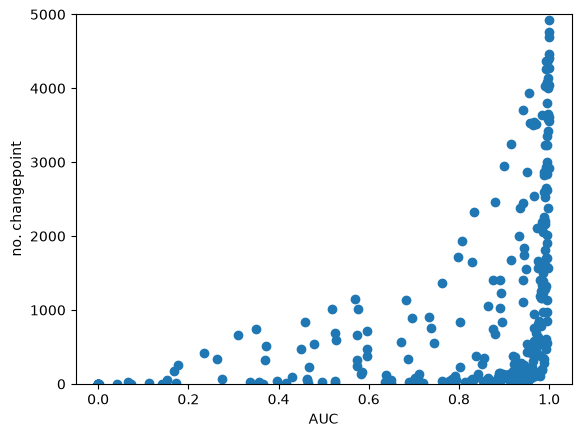

In [8]:
plt.scatter(MODEL_DF["auc"], MODEL_DF["num_changepoint"])
plt.ylim([0, 5000])
plt.xlabel("AUC")
_ = plt.ylabel("no. changepoint")

There are 10 coincident points at (0, 0)

Text(0.5, 0, 'num. changepoint')

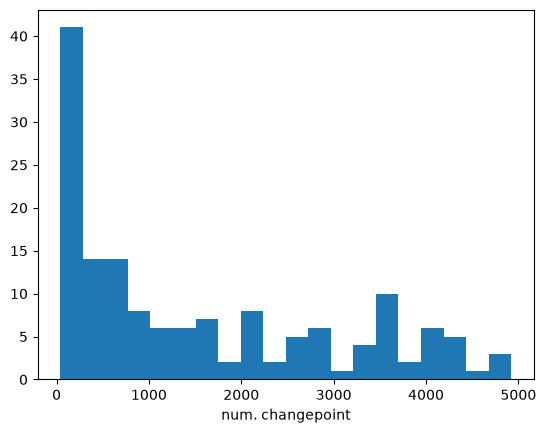

In [9]:
# Histogram of number of changepoints for high AUC models
ser = MODEL_DF[ (MODEL_DF["auc"] > 0.95) ] [ "num_changepoint"]
plt.hist(ser, bins = 20)
plt.xlabel("num. changepoint")

# Timecourse plots

In [10]:
MODEL_DF [ MODEL_DF[cn.COL_NUM_CHANGEPOINT] <= 10 ][[cn.COL_SYSTEM_ID, cn.COL_AUC, cn.COL_P50, cn.COL_NUM_CHANGEPOINT]]

,system_id,auc,p50,num_changepoint
4,BIOMD0000000278,0.000000,0.999934,0
2524,BIOMD0000000342,0.000000,0.999991,0
1326,BIOMD0000000666,0.000700,0.946121,1
1331,BIOMD0000000671,0.000000,0.836006,0
3854,BIOMD0000000676,0.416076,0.854459,9
78,BIOMD0000000677,0.000000,0.922101,0
7641,BIOMD0000000698,0.766281,0.898506,10
125,BIOMD0000000736,0.000000,1.000000,0
132,BIOMD0000000745,0.000000,0.983569,0
164,BIOMD0000000777,0.000000,0.982944,0


# Illustration of the different model types

In [11]:
t_iter = TimecourseIterator(first_model_num=278, last_model_num=278)
item = list(t_iter)[0]
ser = MODEL_DF [MODEL_DF[cn.COL_SYSTEM_ID] == item.model_name].iloc[0]
ser

system_id                                            BIOMD0000000278
num_changepoint                                                    0
auc                                                              0.0
p50                                                         0.999934
max                                                         0.999978
min                                                         0.999918
filename           piecewise_predictions__numpoint_100000__thresh...
changepoints                                                      []
CPF                                                              0.0
Name: 4, dtype: object

In [12]:
mask = (MODEL_DF["auc"] > 0.3) & (MODEL_DF["auc"] < 0.6)
df = MODEL_DF[mask][[cn.COL_SYSTEM_ID, cn.COL_P50, cn.COL_NUM_CHANGEPOINT]]
MODEL_COLLECTION = [Model.getBiomodelNum(v) for v in df[cn.COL_SYSTEM_ID].values]
MODEL_COLLECTION = list(df[cn.COL_SYSTEM_ID].values)
MODEL_DF[mask][[cn.COL_SYSTEM_ID, cn.COL_AUC, cn.COL_P50, cn.COL_NUM_CHANGEPOINT]]

,system_id,auc,p50,num_changepoint
6310,BIOMD0000000461,0.518874,0.964686,1012
7588,BIOMD0000000571,0.582206,0.999651,140
3004,BIOMD0000000665,0.596399,0.862597,375
3854,BIOMD0000000676,0.416076,0.854459,9
8464,BIOMD0000000679,0.463581,0.894006,62
4277,BIOMD0000000680,0.463533,0.894006,54
5547,BIOMD0000000690,0.568621,0.953342,1144
4713,BIOMD0000000699,0.584846,0.906572,158
6402,BIOMD0000000715,0.309775,0.922616,658
1813,BIOMD0000000750,0.356612,0.875803,20


Model 671 gets different accuracy than recorded.

In [14]:
def runner(model_collection):
    t_iter = TimecourseIterator(model_collection=model_collection)
    for item in t_iter:
        analyzer = PSDPredictionAnalyzer(item.model_name)
        try:
            psd = analyzer.makeBestPSD()
        except Exception as e:
            print(f"Could not process {item.model_name}: {e}")
            continue
        title_additional = f"maxred={analyzer.best_model_ser[cn.COL_MAX_FRACTIONAL_REDUCTION]}"
        result = psd.plotPiecewise(legend=False, num_true_point=60, is_nochangepoint_plot=False,
                title_additional=title_additional)
        plt.savefig(f"changepoint_timecourse_{psd.model_num}.pdf")
        _ = plt.figure()

# Tests
runner([5])

Could not process BIOMD0000000005: can only concatenate list (not "str") to list
